# STN with clustered locations: permutation vs. embedding space
Search Trajectory Network (Ochoa, Malan, Blum 2021) of GA elites. Location = Voronoi cell of one of k centers drawn from the elites themselves; permutation space uses the edge distance, embedding space the L2 distance between contrastive-encoder embeddings of the same centers. Both STNs share node positions (MDS of the centers' edge distances), color scale and size scale.

All logic lives in `dl_permutations.stn_clusters`. If `outputs/` is empty, the first run generates the trajectories and trains the encoder.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == 'notebooks':
    os.chdir("..")

In [2]:
import torch
from dl_permutations import stn_clusters as S

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data, model, Z = S.load_inputs(device)
val_runs, _ = S.split_runs()

In [3]:
results = [S.analyse_k(data, Z, k) for k in S.STN_N_CENTERS]
S.print_tables([S.summary_row(res, data, Z, val_runs) for res in results])

 k  ties  same   ari   ami   nmi same_val ari_val ami_val nmi_val seq_sim seq_equal end_equal ari_km ami_km nmi_km
 5 0.266 0.229 0.013 0.008 0.011    0.254   0.028   0.033   0.049   0.257     0.000     0.220  0.002  0.004  0.007
10 0.344 0.159 0.011 0.015 0.026    0.200   0.039   0.047   0.102   0.174     0.000     0.130  0.011  0.024  0.035
20 0.368 0.153 0.020 0.047 0.083    0.166   0.070   0.128   0.273   0.133     0.000     0.140  0.019  0.054  0.089
50 0.385 0.167 0.034 0.123 0.262    0.166   0.110   0.229   0.534   0.123     0.000     0.160  0.039  0.141  0.281

 k        metric  perm   emb   diff
 5       n_total     5     5      0
 5        n_best     1     1      0
 5         n_end     4     5      1
 5 best_strength 0.970 0.620 -0.350
10       n_total    10    10      0
10        n_best     1     1      0
10         n_end     7    10      3
10 best_strength 0.950 0.410 -0.540
20       n_total    20    20      0
20        n_best     1     1      0
20         n_end    11    19

`ties`: share of elites equidistant (edge distance) to several centers, resolved by the lowest center index. `same` / `ari` / `nmi`: label agreement between the spaces on all runs, `*_val` the same on validation runs only (the encoder never saw them). `seq_sim`: mean per-run 1 - Levenshtein / max length of the collapsed location sequences, `seq_equal`: share of runs with identical sequences, `end_equal`: share of runs ending in the same location. `ari_km` / `nmi_km`: k-means in embedding space against the permutation-space labels (control). Second table: STN metrics in both spaces, `diff` = embedding - permutation.

## STNs, same centers in both spaces

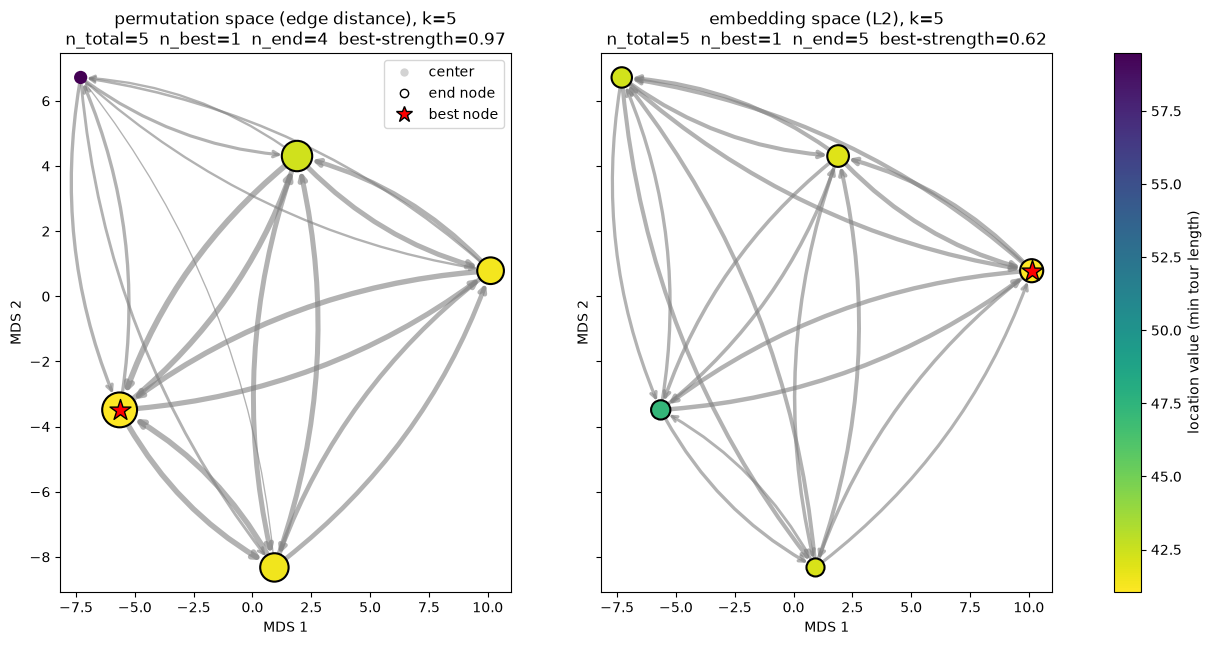

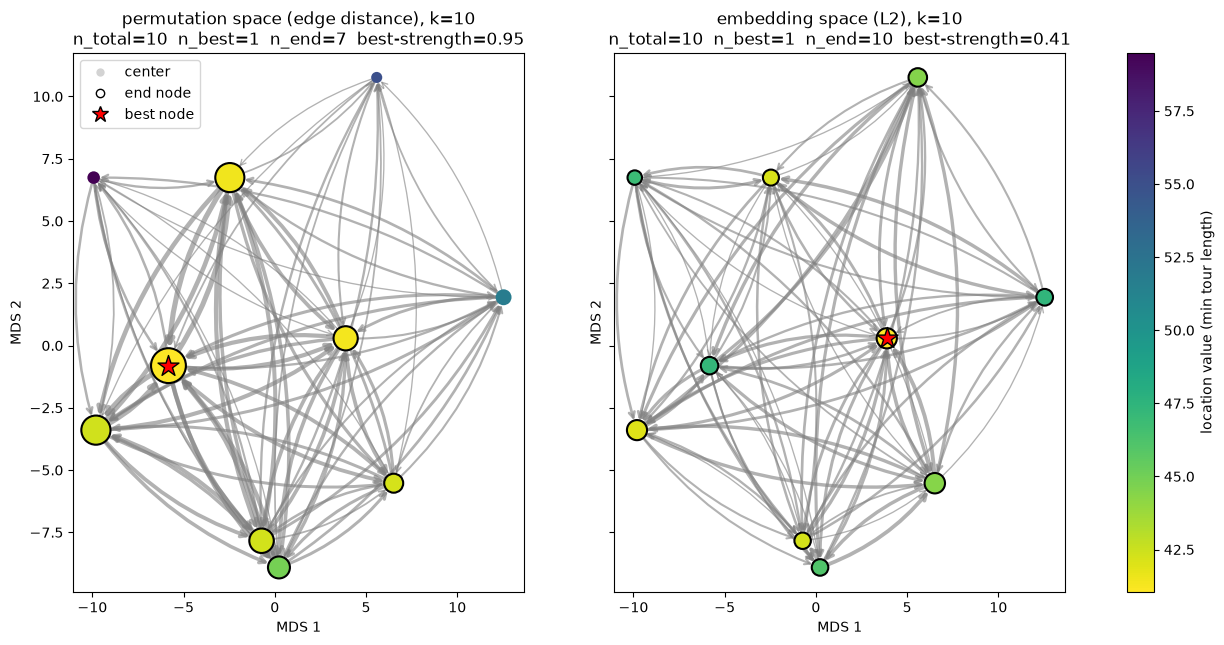

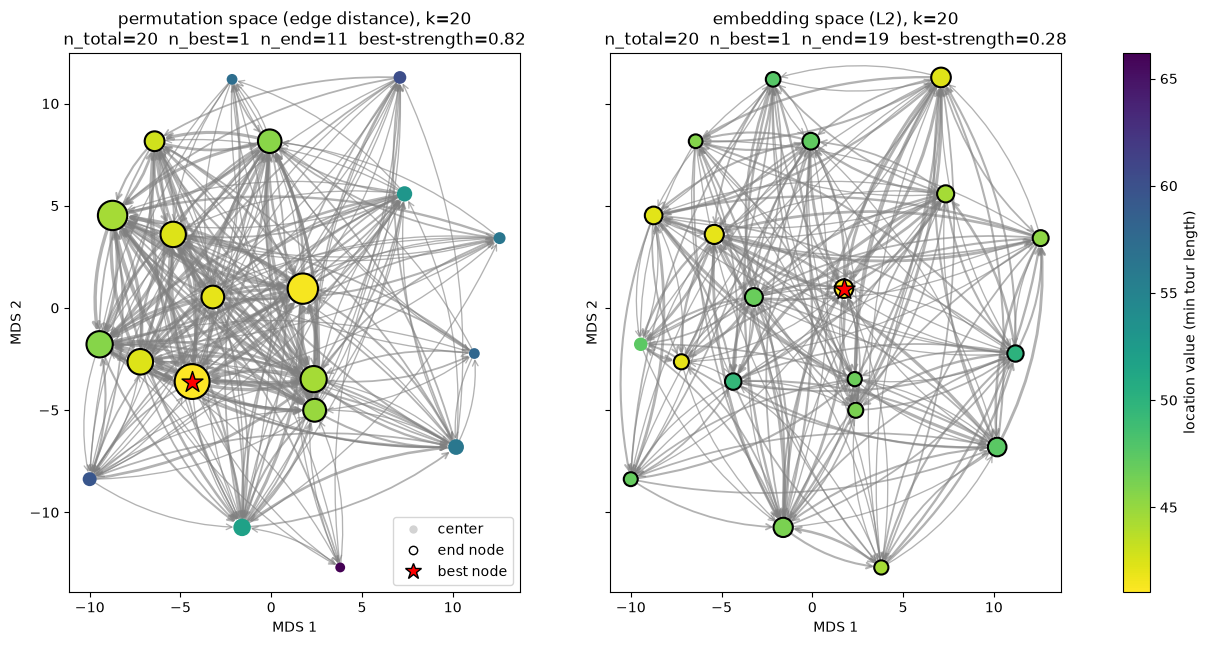

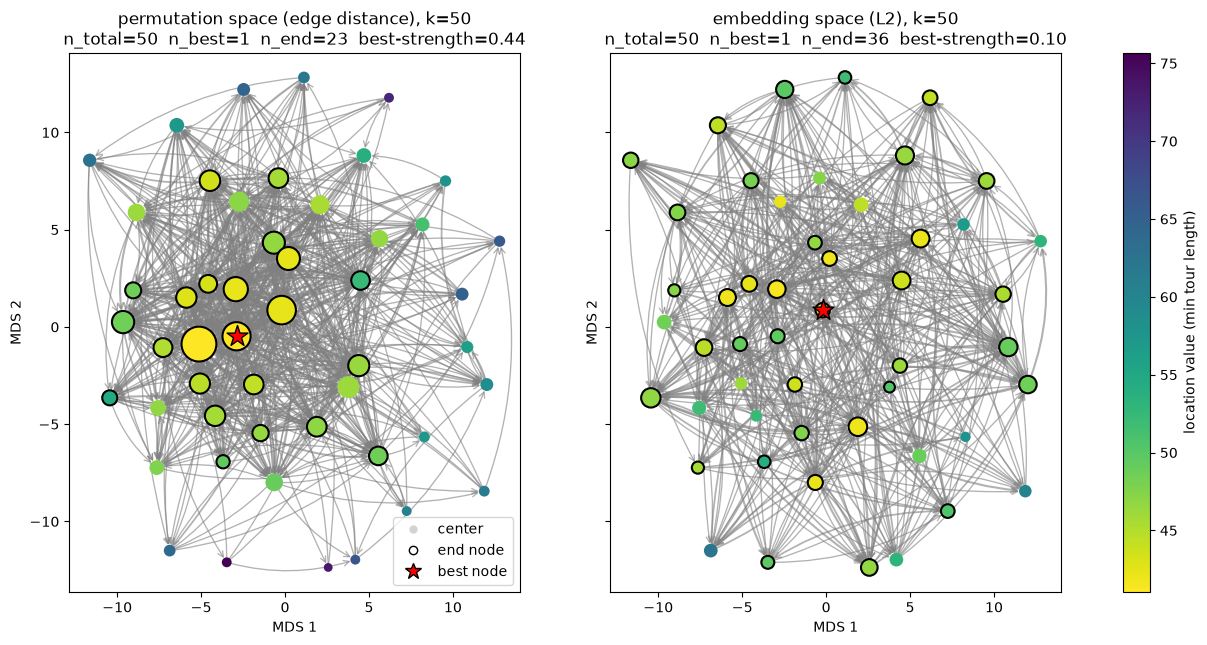

In [4]:
for res in results:
    S.plot_comparison(res, S.STN_PLOT_PATH.format(res["k"]))

## Location confusion, permutation vs. embedding space (k = 10)

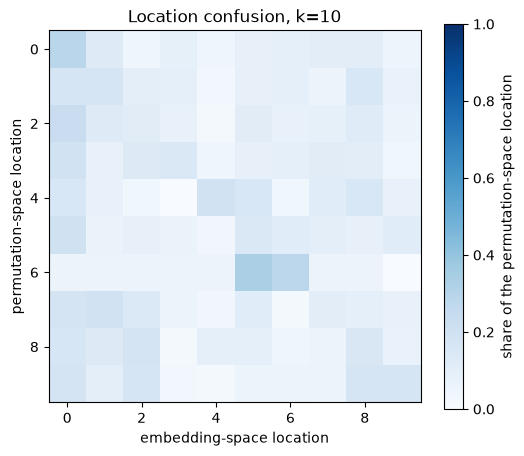

In [5]:
S.plot_confusion(results[1]);

## Variant: dominant location of the whole population (k = 10)
Representative = location holding most of the population instead of the elite's location (permutation space only); its value is the shortest tour of the population inside that location.

elite:    {'n_total': 10, 'n_best': 1, 'n_end': 7, 'best_strength': 0.95}
dominant: {'n_total': 10, 'n_best': 1, 'n_end': 7, 'best_strength': 0.98}


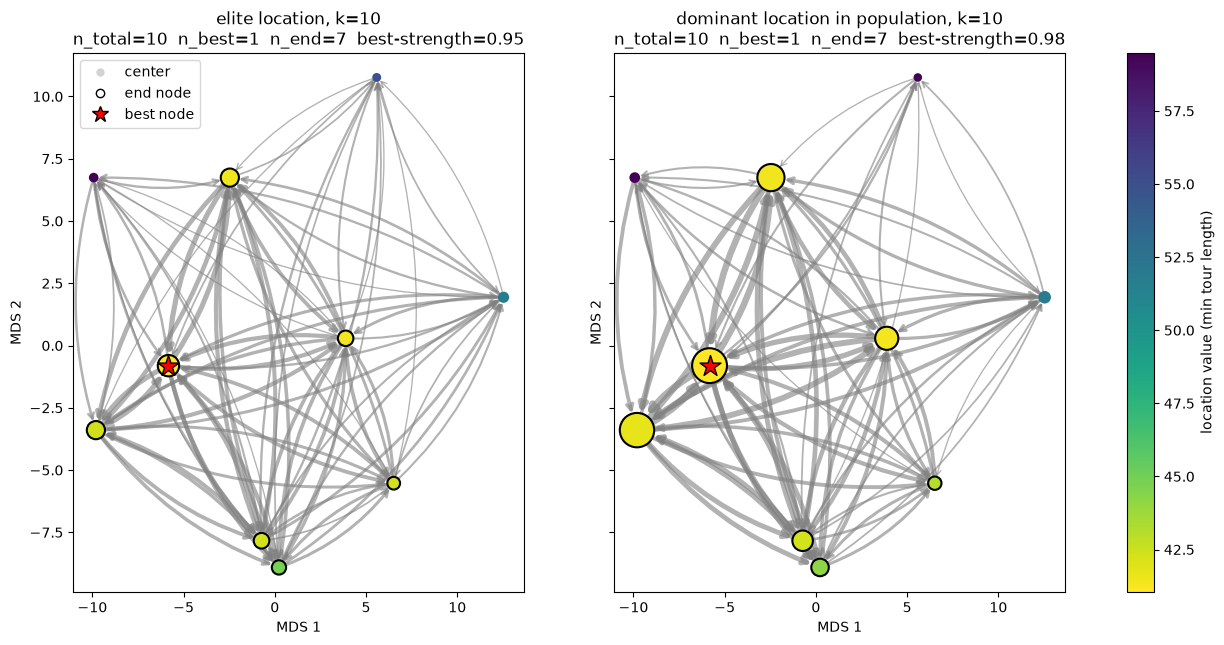

In [6]:
populations = S.load_or_generate_populations()
raw = S.load_or_generate_trajectories()
res = results[1]
dominant, value = S.dominant_population_labels(populations, data["perm"][res["centers"]])
G_dominant = S.build_stn(dominant.ravel(), raw["run_id"], value.ravel())
print("elite:   ", S.stn_metrics(res["G_perm"]))
print("dominant:", S.stn_metrics(G_dominant))
S.plot_stns((res["G_perm"], G_dominant), ("elite location, k=10", "dominant location in population, k=10"), res["pos"]);